# FlowSOM – Kaluza-Ereignisexporte aus Fibroblastengates

Startworkflow für die beiden gelieferten kompensierten CSVs. Ausgangspunkt ist die vom Nutzer in Kaluza ausgewählte Population. Das Notebook prüft NICHT nachträglich, ob Singlets, Viabilität und CD90-Gating korrekt durchgeführt wurden. Bereits kompensierte Daten werden nicht erneut kompensiert.

**Explorativer Workflow:** Cluster sind zunächst rechnerische Gruppen, keine validierten Subtypen. Unstained-Kontrollen werden nicht mitgeclustert; Hintergrund, Positivitätsgrenzen und ΔMFI sind gesonderte Auswertungen. Ohne Kontrollen keine positiven/negativen Clusterbezeichnungen vergeben.

Panel CAF: CD95, CD87, Ly6C, CD39, CD44, CD49b. Panel Intra: α-SMA, Ly6A/E, FAP, CD39, CD140a. CD90 wird nicht als Clusteringmerkmal verwendet, aber in den Markerzusammenfassungen mitgeführt. Separate Röhrchen bleiben separate Analysen. Keine Rekonstruktion von nicht gemeinsam gemessener Koexpression.

## Installation
```bash
python -m pip install flowsom anndata numpy pandas matplotlib seaborn umap-learn jupyter
```
Verwendet wird das SaeysLab-Paket `flowsom`, nicht `pyFlowSOM`. API-Grundlage: https://flowsom.readthedocs.io/en/stable/notebooks/example.html

Ausführungsstatus bei Erstellung: CSV-Import und Vorverarbeitung mit den Originaldateien geprüft. FlowSOM und UMAP konnten in der Erstellungsumgebung nicht vollständig ausgeführt werden; lokal installieren und zunächst einen Pilotlauf prüfen.

In [1]:
from pathlib import Path
import json
import warnings
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import flowsom as fs
from umap import UMAP
from IPython.display import display

for package in ["flowsom", "anndata", "numpy", "pandas", "umap-learn"]:
    print(package, importlib.metadata.version(package))

flowsom 0.2.2
anndata 0.12.19
numpy 2.4.6
pandas 2.3.3
umap-learn 0.5.12


In [5]:
import sys
print(sys.executable)


/home/tom/anaconda3/envs/standard/bin/python


## 1. Konfiguration
`DATA_DIR` auf den CSV-Ordner setzen. Die Standard-Dateimuster wählen CAF beziehungsweise Intra. Unstained, FMO, Isotypkontrollen und doppelte Exporte nicht in diese Ordnerauswahl aufnehmen.

`SIGNAL` wählt A oder H, niemals beide gleichzeitig. Vorbelegt ist A; bei einer etablierten H-Auswertung auf H umstellen und für alle Proben konsistent halten.



In [5]:
DATA_DIR = Path("/home/tom/Downloads/SC_analysis/")
OUTPUT_DIR = Path("flowsom_results")
SIGNAL = "A"  # alternativ "H"
SEED = 42
N_METACLUSTERS = 6  # explorative Auflösung, keine Annahme von sechs echten Subtypen
SOM_X = SOM_Y = 6
MAX_TRAIN_PER_SAMPLE = 10_000
UMAP_MAX_CELLS = 10_000
PILOT_COFACTOR = 1_000.0

PANELS = {
    "CAF": {
        "pattern": "*CAF*.csv",
        "markers": {"CD95": "CD95 FITC", "CD87": "CD87 APC",
                    "Ly6C": "Ly-6C APC-A700", "CD39": "CD39 Violet610",
                    "CD44": "CD44 ECD", "CD49b": "CD49b PC7"},
    },
    "Intra": {
        "pattern": "*Intra*.csv",
        "markers": {"alphaSMA": "aSMA FITC", "Ly6AE": "Ly-6A/E PerCP",
                    "FAP": "FAP APC", "CD39": "CD39 Violet610",
                    "CD140a": "CD140a PE"},
    },
}
# Optional: fixe Cofaktoren pro Panel und Marker; sonst PILOT_COFACTOR.
COFACTORS = {"CAF": {}, "Intra": {}}

# Optionales CSV: sample_id, animal_id, sex, age_weeks, tnf, dose_Gy, batch.
# sample_id muss exakt dem Dateinamen ohne .csv entsprechen.
METADATA_FILE = None
warnings.warn("Pilottransformation: Cofaktor und A/H-Wahl vor biologischer Interpretation prüfen.")

/tmp/ipykernel_155086/3974152745.py:31: UserWarning: Pilottransformation: Cofaktor und A/H-Wahl vor biologischer Interpretation prüfen.
  warnings.warn("Pilottransformation: Cofaktor und A/H-Wahl vor biologischer Interpretation prüfen.")


In [4]:
print("Datenordner:", DATA_DIR.resolve())
print("Ordner vorhanden:", DATA_DIR.is_dir())

print("CAF-Dateien:")
print([p.name for p in DATA_DIR.glob("*CAF*.csv")])

print("Intra-Dateien:")
print([p.name for p in DATA_DIR.glob("*Intra*.csv")])

Datenordner: /home/tom/Downloads/SC_analysis
Ordner vorhanden: True
CAF-Dateien:
[]
Intra-Dateien:
[]


## 2. Import, Kanalzuordnung und QC
Kaluza-Format: Semikolon als Trennzeichen und Dezimalkomma. Ungültige Zahlen führen zum Abbruch. Ereignis-ID = Zeilennummer im Export (1-basiert), nicht automatisch das ursprüngliche FCS-Ereignis. Keine automatische Hintergrundsubtraktion, keine zusätzliche Kompensation, keine erneuten Gates.

,sample_id,channel,n_events,negative_fraction,q01,median,q99
0,118CAF_Haut_nonTNF_0Gy-B1 viable,CD95 FITC-A,15397,0.000000,4458.505400,22131.490,263686.140
1,118CAF_Haut_nonTNF_0Gy-B1 viable,CD87 APC-A,15397,0.000000,4129.692000,26431.760,443051.828
2,118CAF_Haut_nonTNF_0Gy-B1 viable,Ly-6C APC-A700-A,15397,0.000325,944.625152,29242.080,787391.268
3,118CAF_Haut_nonTNF_0Gy-B1 viable,CD39 Violet610-A,15397,0.000000,5803.836840,23557.570,233817.952
4,118CAF_Haut_nonTNF_0Gy-B1 viable,CD44 ECD-A,15397,0.000065,24020.655200,223235.300,2523144.440
5,118CAF_Haut_nonTNF_0Gy-B1 viable,CD49b PC7-A,15397,0.138923,-7595.512800,1723.671,144012.496
6,118CAF_Haut_nonTNF_0Gy-B1 viable,CD90.2 PB450-A,15397,0.000130,122662.336000,838680.600,3444123.560


CAF {'118CAF_Haut_nonTNF_0Gy-B1 viable': 15397}


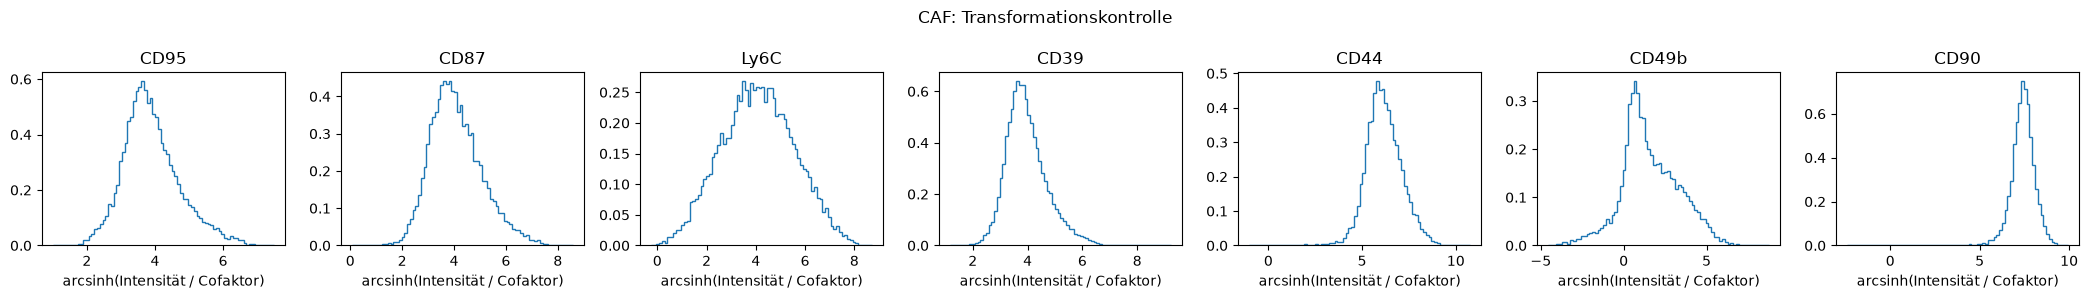

,sample_id,channel,n_events,negative_fraction,q01,median,q99
0,119Intra_Haut_nonTNF_0Gy-C1 viable,aSMA FITC-A,11673,0.000000,54324.64200,1640357.000,2.085341e+07
1,119Intra_Haut_nonTNF_0Gy-C1 viable,Ly-6A/E PerCP-A,11673,0.000000,25595.33200,658863.000,4.086189e+06
2,119Intra_Haut_nonTNF_0Gy-C1 viable,FAP APC-A,11673,0.227705,-5225.94776,1457.264,2.623183e+04
3,119Intra_Haut_nonTNF_0Gy-C1 viable,CD39 Violet610-A,11673,0.000000,3926.41116,16167.810,1.262271e+05
4,119Intra_Haut_nonTNF_0Gy-C1 viable,CD140a PE-A,11673,0.000343,2313.11416,109443.000,9.954085e+05
5,119Intra_Haut_nonTNF_0Gy-C1 viable,CD90.2 PB450-A,11673,0.000000,12106.13400,694514.600,2.401686e+06


Intra {'119Intra_Haut_nonTNF_0Gy-C1 viable': 11673}


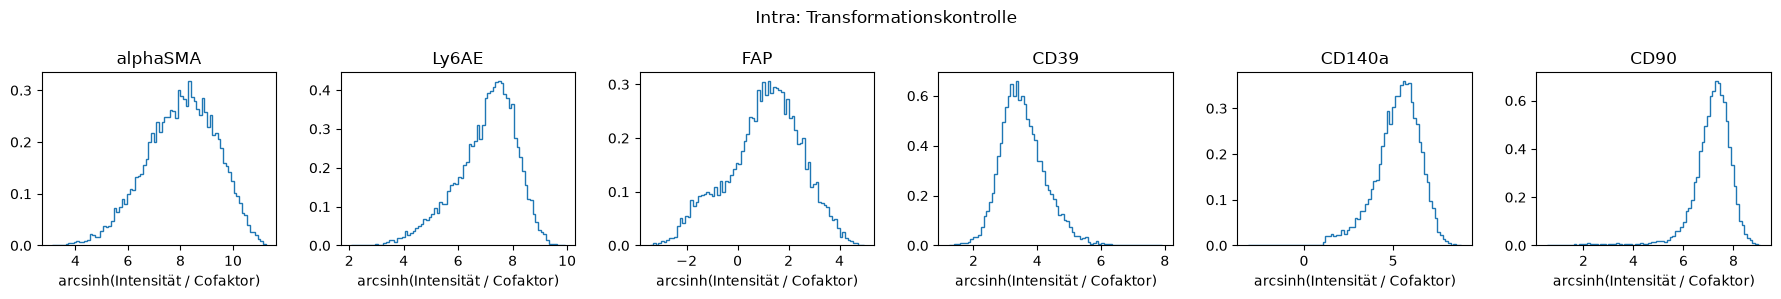

In [6]:
def load_panel(panel, config):
    files = sorted(DATA_DIR.glob(config["pattern"]))
    if not files:
        raise FileNotFoundError(f"Keine Dateien für {panel}: {config['pattern']}")
    mapping = {f"{channel}-{SIGNAL}": marker
               for marker, channel in config["markers"].items()}
    mapping[f"CD90.2 PB450-{SIGNAL}"] = "CD90"
    tables, qc = [], []
    for path in files:
        if any(word in path.stem.lower() for word in ["unstained", "fmo", "isotype"]):
            raise ValueError(f"Kontrolldatei nicht mitclustern: {path.name}")
        raw = pd.read_csv(path, sep=";", decimal=",", encoding="utf-8-sig")
        raw.columns = raw.columns.str.strip()
        if raw.columns.duplicated().any():
            raise ValueError(f"{path.name}: doppelte Spaltennamen")
        missing = set(mapping) - set(raw.columns)
        if missing:
            raise ValueError(f"{path.name}: Kanäle fehlen: {sorted(missing)}")
        numeric = raw.apply(pd.to_numeric, errors="raise")
        if numeric.empty or not np.isfinite(numeric.to_numpy()).all():
            raise ValueError(f"{path.name}: leere oder nicht-endliche Ereignisdaten")
        selected = numeric[list(mapping)].rename(columns=mapping)
        selected.insert(0, "event_id", np.arange(1, len(selected)+1))
        selected.insert(0, "sample_id", path.stem)
        tables.append(selected)
        for channel in mapping:
            v = numeric[channel]
            qc.append({"sample_id": path.stem, "channel": channel,
                       "n_events": len(v), "negative_fraction": float((v < 0).mean()),
                       "q01": v.quantile(.01), "median": v.median(),
                       "q99": v.quantile(.99)})
    return pd.concat(tables, ignore_index=True), pd.DataFrame(qc)


def transform_panel(raw, panel, marker_names):
    transformed = raw.copy()
    for marker in marker_names + ["CD90"]:
        cofactor = float(COFACTORS[panel].get(marker, PILOT_COFACTOR))
        if not np.isfinite(cofactor) or cofactor <= 0:
            raise ValueError(f"Ungültiger Cofaktor für {panel}/{marker}")
        transformed[marker] = np.arcsinh(raw[marker].to_numpy() / cofactor)
    return transformed


raw_panels, transformed_panels = {}, {}
for panel, config in PANELS.items():
    raw, qc = load_panel(panel, config)
    transformed = transform_panel(raw, panel, list(config["markers"]))
    raw_panels[panel], transformed_panels[panel] = raw, transformed
    folder = OUTPUT_DIR / panel
    folder.mkdir(parents=True, exist_ok=True)
    qc.to_csv(folder / "input_qc.csv", index=False)
    display(qc)
    print(panel, raw.groupby("sample_id").size().to_dict())
    markers = list(config["markers"]) + ["CD90"]
    fig, axes = plt.subplots(1, len(markers), figsize=(3*len(markers), 3))
    for ax, marker in zip(np.atleast_1d(axes), markers):
        for sample, values in transformed.groupby("sample_id"):
            ax.hist(values[marker], bins=80, histtype="step", density=True, label=sample)
        ax.set_title(marker)
        ax.set_xlabel("arcsinh(Intensität / Cofaktor)")
    fig.suptitle(f"{panel}: Transformationskontrolle")
    fig.tight_layout()
    fig.savefig(folder / "transformation_qc.png", dpi=150, bbox_inches="tight")
    plt.show()

## 3. Gemeinsames Referenzmodell je Panel
Pro Probe wird dieselbe Maximalzahl zufälliger Ereignisse zum Training verwendet. Kleinere Proben liefern alle verfügbaren Ereignisse. Alle importierten Bedingungen eines Panels teilen ein Modell; getrenntes Neutraining pro Kohorte würde keine direkt vergleichbaren Cluster-IDs liefern.


In [7]:
results = {}
for panel, config in PANELS.items():
    raw = raw_panels[panel]
    table = transformed_panels[panel]
    markers = list(config["markers"])
    rng = np.random.default_rng(SEED)
    train_indices = np.concatenate([
        rng.choice(group.index.to_numpy(), min(len(group), MAX_TRAIN_PER_SAMPLE), replace=False)
        for _, group in table.groupby("sample_id", sort=True)
    ])
    def make_adata(frame):
        values = frame[markers].to_numpy(dtype=np.float32)
        obs = frame[["sample_id", "event_id"]].copy()
        obs.index = pd.Index([f"event_{i}" for i in frame.index], dtype=str)
        var = pd.DataFrame({"channel": markers, "marker": markers}, index=markers)
        return ad.AnnData(X=values, obs=obs, var=var)

    train_data = make_adata(table.loc[train_indices])
    model = fs.FlowSOM(train_data, cols_to_use=markers,
                       n_clusters=N_METACLUSTERS, xdim=SOM_X, ydim=SOM_Y, seed=SEED)
    mapped = model.new_data(make_adata(table))
    assignments = mapped.get_cell_data().obs
    required = {"clustering", "metaclustering"}
    if not required.issubset(assignments.columns) or len(assignments) != len(table):
        raise RuntimeError("Unerwartete FlowSOM-API/Rückgabe; Paketversion prüfen.")
    annotated = raw.copy()
    annotated["som_node"] = assignments["clustering"].to_numpy()
    annotated["metacluster"] = assignments["metaclustering"].to_numpy()
    results[panel] = {"model": model, "annotated": annotated,
                      "transformed": table, "markers": markers}
    print(panel, annotated["metacluster"].value_counts().sort_index().to_dict())

/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)
2026-11-09 11:27:04.346 | DEBUG    | flowsom.main:__init__:82 - Reading input.
2026-11-09 11:27:04.3

CAF {0: 1695, 1: 3760, 2: 7931, 3: 207, 4: 1389, 5: 415}


/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/mudata/_core/mudata.py:613: UserWarning: Cannot join columns with the same name because var_names are intersecting.
  self._update_attr_legacy(attr, axis, join_common, **kwargs)
/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the d

Intra {0: 1936, 1: 4632, 2: 2644, 3: 1236, 4: 563, 5: 662}


## 4. Tabellen, Heatmaps und UMAP
Rohintensitäts-Mittel und -Mediane bleiben getrennt von transformierten Werten. Keine ΔMFI ohne passende Hintergrundkontrolle. Heatmap-Z-Scores werden ausschließlich zur Darstellung pro Marker über die Clustermediane berechnet, nicht zum Clustering. UMAP ist eine explorative Visualisierung, kein Cluster- oder Signifikanztest. Keine Zellzahl als biologische Replikatzahl verwenden.

metacluster,0,1,2,3,4,5
sample_id,,,,,,
118CAF_Haut_nonTNF_0Gy-B1 viable,11.008638,24.420342,51.510034,1.344418,9.021238,2.69533


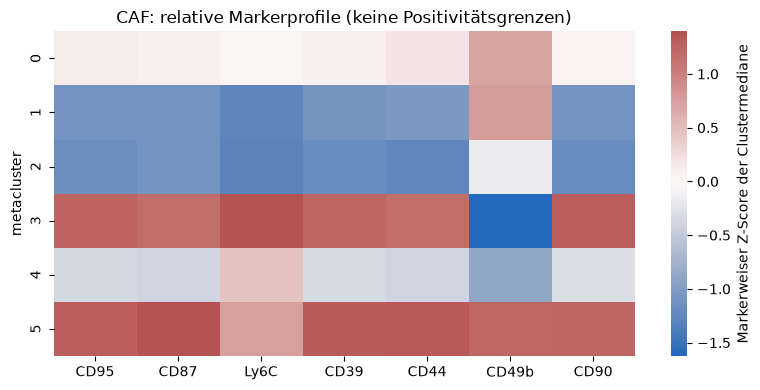

/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


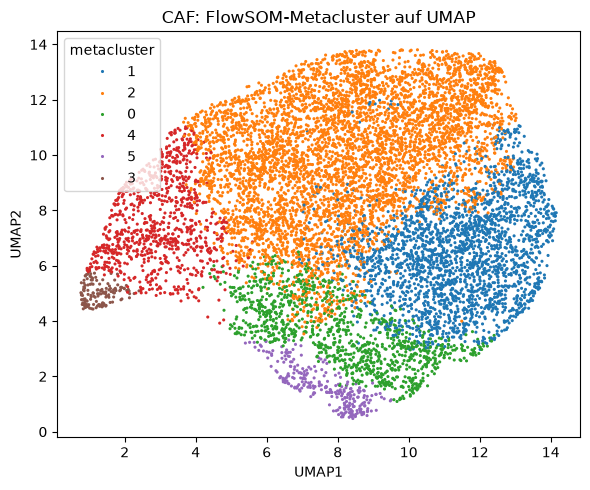

metacluster,0,1,2,3,4,5
sample_id,,,,,,
119Intra_Haut_nonTNF_0Gy-C1 viable,16.585282,39.681316,22.650561,10.588538,4.823096,5.671207


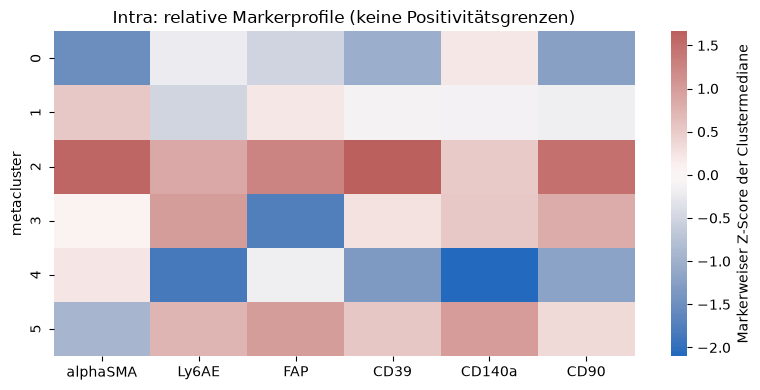

/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


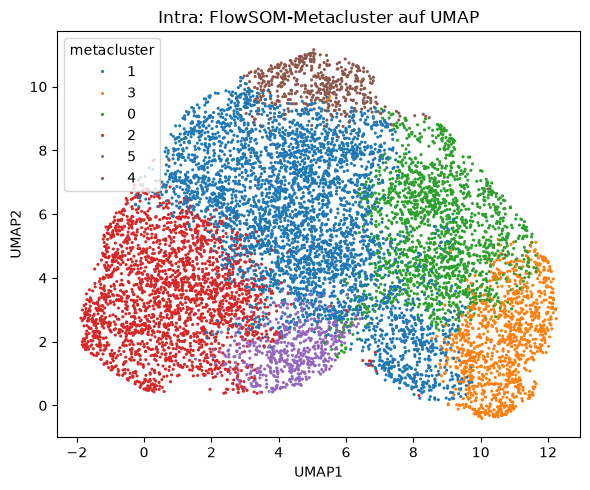

In [8]:
for panel, result in results.items():
    folder = OUTPUT_DIR / panel
    events = result["annotated"]
    transformed = result["transformed"].copy()
    markers = result["markers"]
    report_markers = markers + ["CD90"]
    transformed["metacluster"] = events["metacluster"].to_numpy()
    events.to_csv(folder / "events_raw_with_clusters.csv.gz", index=False, compression="gzip")
    counts = pd.crosstab(events.sample_id, events.metacluster).reindex(
        columns=range(N_METACLUSTERS), fill_value=0)
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    counts.to_csv(folder / "counts_per_sample.csv")
    percentages.to_csv(folder / "percentages_per_sample.csv")
    for statistic in ["mean", "median"]:
        summary = events.groupby(["sample_id", "metacluster"])[report_markers].agg(statistic)
        summary.to_csv(folder / f"raw_{statistic}_per_sample_cluster.csv")
    transformed.groupby(["sample_id", "metacluster"])[report_markers].median().to_csv(
        folder / "transformed_median_per_sample_cluster.csv")
    if METADATA_FILE is not None:
        metadata = pd.read_csv(METADATA_FILE, dtype={"sample_id": str})
        if metadata.sample_id.duplicated().any():
            raise ValueError("Probenmetadaten enthalten doppelte sample_id")
        if not set(events.sample_id).issubset(set(metadata.sample_id)):
            raise ValueError("Metadaten fehlen für mindestens eine Probe")
        percentages.reset_index().merge(metadata, on="sample_id", validate="one_to_one").to_csv(
            folder / "percentages_with_metadata.csv", index=False)
    display(percentages)
    median = transformed.groupby("metacluster")[report_markers].median()
    zscore = (median - median.mean()) / median.std(ddof=0).replace(0, np.nan)
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.heatmap(zscore.fillna(0), cmap="vlag", center=0, ax=ax,
                cbar_kws={"label": "Markerweiser Z-Score der Clustermediane"})
    ax.set_title(f"{panel}: relative Markerprofile (keine Positivitätsgrenzen)")
    fig.tight_layout(); fig.savefig(folder / "marker_heatmap.png", dpi=200)
    plt.show()
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(events), min(len(events), UMAP_MAX_CELLS), replace=False)
    coordinates = UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit_transform(
        transformed.iloc[idx][markers].to_numpy())
    embedding = events.iloc[idx][["sample_id", "event_id", "metacluster"]].copy()
    embedding["UMAP1"], embedding["UMAP2"] = coordinates[:, 0], coordinates[:, 1]
    embedding.to_csv(folder / "umap_subset.csv", index=False)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.scatterplot(data=embedding, x="UMAP1", y="UMAP2",
                    hue=embedding.metacluster.astype(str), s=5, linewidth=0, ax=ax)
    ax.set_title(f"{panel}: FlowSOM-Metacluster auf UMAP")
    fig.tight_layout(); fig.savefig(folder / "umap_metaclusters.png", dpi=200)
    plt.show()
    parameters = {"signal": SIGNAL, "seed": SEED, "markers": markers,
                  "pilot_cofactor": PILOT_COFACTOR, "cofactors": COFACTORS[panel],
                  "n_metaclusters": N_METACLUSTERS, "som_grid": [SOM_X, SOM_Y],
                  "max_train_per_sample": MAX_TRAIN_PER_SAMPLE,
                  "versions": {pkg: importlib.metadata.version(pkg)
                               for pkg in ["flowsom", "anndata", "numpy", "pandas", "umap-learn"]}}
    (folder / "parameters.json").write_text(json.dumps(parameters, indent=2), encoding="utf-8")